# DLog-QML

## Can mathematical structure make quantum kernels learnable?

---

We built a binary classification task where the label is easy to describe in one
coordinate system and, as far as we can tell, invisible in another. The two coordinates are
related by a discrete logarithm: the label depends on $\log_g h$, and the model only ever
sees $h = g^x \bmod p$.

The eleven tested classical models remain close to chance on this task. So does a strong
generic quantum kernel. A quantum feature map built around the group structure that produced
the encoding gets close to perfect. That gap is the whole result, and most of this notebook
is us trying to make it go away.

The framing matters, so to be blunt about it up front: this is a **representation**
experiment, not a speedup experiment. We are asking whether matching a quantum feature map
to the algebra of a problem changes what a kernel method can learn. We are not solving
discrete logarithms, not running on hardware, and not claiming a computational advantage.
The prime we use ($p = 1019$) is small enough that our own test suite cracks it with
baby-step giant-step as an integrity check.

What follows: the setup, the dataset and its leakage boundary, the baselines, the two
quantum kernels, then four controls designed to invalidate the result, then the statistics,
ablations, and kernel geometry. Every number is either computed while the notebook runs or
loaded from a stored artifact that is labelled as stored.

## The experiment in 60 seconds

If you only read one cell, read the next one. The numbers in it come from the stored
20-seed artifact via `dlog_qml.audit`, which recomputes every derived quantity rather than
reading a summary field. Everything is re-derived from scratch further down.

In [1]:
import os, sys, json, warnings
import numpy as np
import pandas as pd

sys.path.insert(0, os.path.join(os.getcwd(), "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

# --- switches ---------------------------------------------------------------
RUN_FRESH_EXPERIMENT = False   # True -> recompute the sweeps (~3.5 min)
FAST_MODE            = False   # True -> 8 qubits, smaller dataset

from dlog_qml.config import ExperimentConfig
from dlog_qml.group import DlogGroup

cfg = ExperimentConfig.load("configs/default.yaml")
if FAST_MODE:
    cfg = cfg.replace(n_qubits=8, n_train=120, n_test=30,
                      extra_baselines=False, n_seeds=5)

RESULTS, FIGURES = cfg.results_dir, cfg.figures_dir
RAW = os.path.join(RESULTS, "raw")
os.makedirs(FIGURES, exist_ok=True)
group = DlogGroup.from_qubits(cfg.n_qubits).build_tables()

# ---- the 60-second card, generated from the stored artifacts ---------------
from dlog_qml.artifacts import load_artifact
from dlog_qml.audit import headline_numbers
from dlog_qml.experiments import COSET_KEY, LADDER_KEY

_run, _p1 = load_artifact(os.path.join(RAW, "single_run.json"))
_ms,  _p2 = load_artifact(os.path.join(RAW, "multi_seed.json"))

print("THE EXPERIMENT IN 60 SECONDS")
print("=" * 64)
print(f"Input            h = g^x mod p,  p = {group.p},  g = {group.g}")
print( "                 the model sees only the bits of h")
print( "Hidden target    a secret half-interval of x = log_g(h)")
print(f"Tested           {cfg.n_train} train / {cfg.n_test} test, exact 50/50, "
       "disjoint exponents")
print( "                 11 classical models, 1 generic quantum kernel,")
print( "                 1 structure-aware coset kernel")

if _run is not None and _ms is not None:
    _n = headline_numbers(_run, multi_seed=_ms)["multi_seed"]
    print()
    print(f"{_n['n_seeds']}-seed result")
    for label, mean, std in (
            ("  coset quantum  ", _n["coset_mean"],           _n["coset_std"]),
            ("  best classical ", _n["best_competitor_mean"], _n["best_competitor_std"]),
            ("  generic quantum", _n["generic_mean"],         _n["generic_std"])):
        print(f"{label}  {mean:.3f} +/- {std:.3f}")
    print()
    print(f"The result       the structure-aware representation wins on "
          f"{_n['seeds_coset_beats_best']}/{_n['n_seeds']} seeds")
    print(f"                 separation {_n['separation_mean']:+.3f} "
          f"+/- {_n['separation_std']:.3f}, worst seed {_n['separation_min']:+.3f}")
else:
    print("\n[stored artifacts not found -- run: python scripts/run_experiment.py]")

print()
print("NOT shown        quantum speedup, hardware advantage, a cryptographic")
print("                 break, or a complexity-theoretic separation")
print("=" * 64)
print(f"[{_p2.source.upper()}]  {_p2.written_at or ''}")

THE EXPERIMENT IN 60 SECONDS
Input            h = g^x mod p,  p = 1019,  g = 2
                 the model sees only the bits of h
Hidden target    a secret half-interval of x = log_g(h)
Tested           200 train / 50 test, exact 50/50, disjoint exponents
                 11 classical models, 1 generic quantum kernel,
                 1 structure-aware coset kernel

20-seed result
  coset quantum    0.989 +/- 0.018
  best classical   0.541 +/- 0.070
  generic quantum  0.503 +/- 0.078

The result       the structure-aware representation wins on 20/20 seeds
                 separation +0.383 +/- 0.062, worst seed +0.240

NOT shown        quantum speedup, hardware advantage, a cryptographic
                 break, or a complexity-theoretic separation
[CACHED]  2026-08-28 22:15:07


## Experiment card

Everything is driven from `configs/default.yaml`.

In [2]:
card = pd.DataFrame([
    ("prime p",              f"{group.p} = 2*{group.q} + 1 (safe prime)"),
    ("group",                f"Z_p*, order {group.order}"),
    ("generator g",          group.g),
    ("qubits",               f"{group.n_bits} (register holds one group element)"),
    ("train / test",         f"{cfg.n_train} / {cfg.n_test}, exact 50/50, disjoint exponents"),
    ("seeds",                cfg.n_seeds),
    ("classical baselines",  "11 (incl. CV-tuned RBF-SVM)"),
    ("quantum kernels",      "coset (structure-aware) + generic ladder (control)"),
    ("kernel evaluation",    "exact statevector simulation, no shot noise"),
    ("hardware",             "none -- classical simulation only"),
    ("master seed",          cfg.seed),
], columns=["", "value"])
display(card.style.hide(axis="index"))
print(f"RUN_FRESH_EXPERIMENT = {RUN_FRESH_EXPERIMENT}   FAST_MODE = {FAST_MODE}")

,value
prime p,1019 = 2*509 + 1 (safe prime)
group,"Z_p*, order 1018"
generator g,2
qubits,10 (register holds one group element)
train / test,"200 / 50, exact 50/50, disjoint exponents"
seeds,20
classical baselines,11 (incl. CV-tuned RBF-SVM)
quantum kernels,coset (structure-aware) + generic ladder (control)
kernel evaluation,"exact statevector simulation, no shot noise"
hardware,none -- classical simulation only


RUN_FRESH_EXPERIMENT = False   FAST_MODE = False


## The research question

> Does a quantum kernel whose feature geometry is matched to the structure of the target
> learn better than generic quantum representations and the classical baselines we tested?

That is a question about representation, not about quantum computers being fast. The
sharper version, which is what the experiments actually answer:

- if we swap the structure-aware feature map for a generic one and change nothing else,
  does the result survive? (Section: *the generic control*)
- is the target genuinely hidden, or did we just encode it awkwardly? (*the Legendre attack*)
- is there any signal in the data at all? (*the oracle*)
- does the structure-aware kernel work on targets it was not matched to? (*mismatched concept*)

If the answer to the first is "yes, it survives", the result is about quantum computing
generally and is much less interesting. It does not survive, which is the point.

## Setup

Work in the multiplicative group $G = \mathbb{Z}_p^{*}$ with $p = 2q+1$ a safe prime and
$g$ a generator. For a hidden exponent $x$,

$$
\underbrace{x \longmapsto h = g^{x} \bmod p}_{\text{cheap}}
\qquad
\underbrace{h \longmapsto x = \log_g h}_{\text{the discrete logarithm problem}}
$$

The forward map is a bijection $\mathbb{Z}_{p-1} \to \mathbb{Z}_p^*$, so nothing is
destroyed. The information is still there; the question is whether it can be recovered
efficiently from the public representation, and that is where the asymptotic hardness
assumption lives — not in the small instance we actually run.

Two details that are easy to get wrong. The largest prime below $2^{10}$ is 1021, but
$1021$ is not *safe* ($510 = 2\cdot3\cdot5\cdot17$), and the generator test we use relies on
safeness. The right choice is $1019$. And because the order of any element divides
$|G| = 2q$, whose divisors are only $\{1,2,q,2q\}$, rejecting $g^2 \equiv 1$ and
$g^q \equiv 1$ is enough to prove $g$ has full order.

In [3]:
from dlog_qml.group import is_safe_prime, largest_safe_prime_below
from dlog_qml.labels import derive_secret

secret = derive_secret(cfg.seed, group.p, group.g)
print(f"1021 prime but safe?  {is_safe_prime(1021)}    -> largest safe prime < 2^10 = "
      f"{largest_safe_prime_below(1024)}")
print(f"g={group.g}:  g^2 != 1 -> {pow(group.g,2,group.p)!=1}    "
      f"g^q != 1 -> {pow(group.g,group.q,group.p)!=1}    (so order = {group.order})")
print(f"secret shift s = {secret}   [SHA-256 of the run seed, mod p-1]")

1021 prime but safe?  False    -> largest safe prime < 2^10 = 1019
g=2:  g^2 != 1 -> True    g^q != 1 -> True    (so order = 1018)
secret shift s = 666   [SHA-256 of the run seed, mod p-1]


The label is a secret half-interval of the exponent:

$$
y(x) = +1 \ \text{ if } \ (x - s) \bmod (p-1) \in \left[0, \tfrac{p-3}{2}\right],
\qquad -1 \ \text{ otherwise.}
$$

With $N = p-1 = 2q$ the upper endpoint is $\tfrac{2q-2}{2} = q-1$, so the positive set is
$\{0,\dots,q-1\}$ and its complement is $\{q,\dots,2q-1\}$ — exactly $q$ each. The concept
is balanced over the entire group, not approximately, which is why the splits below land on
a clean 50/50 without any resampling.

In $\log_g$ coordinates this is simply interval membership on a circle. The difficulty we
are probing is therefore not an obviously complicated label class; it is the representation
available to the learner.

In [4]:
from dlog_qml.labels import HalfIntervalLabel

rule = HalfIntervalLabel(secret_s=secret, order=group.order, q=group.q)
lo, hi = rule.positive_interval
labels_all = rule.vectorised(np.arange(group.order))
print(f"positive interval [{lo}, {hi}] -> {(labels_all==1).sum()} of {group.order} exponents")
print(f"negative                       -> {(labels_all==-1).sum()}")
print(f"balanced over the whole group: {(labels_all==1).sum() == (labels_all==-1).sum()}")

positive interval [0, 508] -> 509 of 1018 exponents
negative                       -> 509
balanced over the whole group: True


## What the model actually sees

```
hidden exponent x        ORACLE ONLY -- never reaches a learner
        |
        |  g^x mod p
        v
group element h          public
        |
        |  LSB-first binary decomposition, fixed width
        v
binary_feature_0 .. 9    <-- the only model input
        |
        v
kernel  ->  SVM  ->  y in {-1, +1}
```

The exponent lives behind `oracle_exponents()`; `features()` returns bits and nothing else.
Exponents are drawn without replacement, so no group element appears in both splits — a
train/test gap cannot be memorisation.

In [5]:
from dlog_qml.data import generate_dataset

data = generate_dataset(n_qubits=cfg.n_qubits, n_train=cfg.n_train,
                        n_test=cfg.n_test, seed=cfg.seed, labeling=cfg.labeling)
audit = data.verify()   # assertions; raises on any violation

print(f"h = g^x mod p re-derived for all {audit['n_samples']} rows")
print(f"balance   train {audit['balance']['train']}   test {audit['balance']['test']}")
print(f"splits disjoint: {audit['splits_disjoint']}   feature width: {audit['feature_width']}")
print(f"independent BSGS discrete-log probes: {audit['bsgs_probes']}")
print()
cols = ["group_element_h"] + [f"binary_feature_{j}" for j in range(6)] + ["label"]
display(data.to_dataframe().head(6)[["sample_id"] + cols])

h = g^x mod p re-derived for all 250 rows
balance   train {'positive': 100, 'negative': 100}   test {'positive': 25, 'negative': 25}
splits disjoint: True   feature width: 10
independent BSGS discrete-log probes: [898, 926, 266]



,sample_id,group_element_h,binary_feature_0,binary_feature_1,binary_feature_2,binary_feature_3,binary_feature_4,binary_feature_5,label
0,0,9,1,0,0,1,0,0,1
1,1,536,0,0,0,1,1,0,1
2,2,372,0,0,1,0,1,1,-1
3,3,652,0,0,1,1,0,0,-1
4,4,305,1,0,0,0,1,1,1
5,5,807,1,1,1,0,0,1,-1


`raw_input_x` ships in the CSV so anyone can recompute the labels themselves, but it is the
trapdoor, not a feature. A guard runs before every model. Rather than trust it, we poison a
column with a bit of $x$ and check that it fires.

In [6]:
from dlog_qml.classical import assert_no_leakage

X = data.features("train")
assert_no_leakage(data, X, "train")
print("clean features    -> guard passes")

poisoned = X.copy()
poisoned[:, 0] = (data.oracle_exponents("train") & 1).astype(float)
try:
    assert_no_leakage(data, poisoned, "train")
    print("poisoned features -> GUARD DID NOT FIRE")
except AssertionError as exc:
    print(f"poisoned features -> guard fires: {exc}")

clean features    -> guard passes
poisoned features -> guard fires: column 0 leaks a bit of the hidden exponent


## The same data, two coordinate systems

This is the clearest way we found to show what the task is. Same points, same kind of
strip, twice — only the horizontal axis changes.

running the reference experiment (~30 s) ...


done in 26.4 s


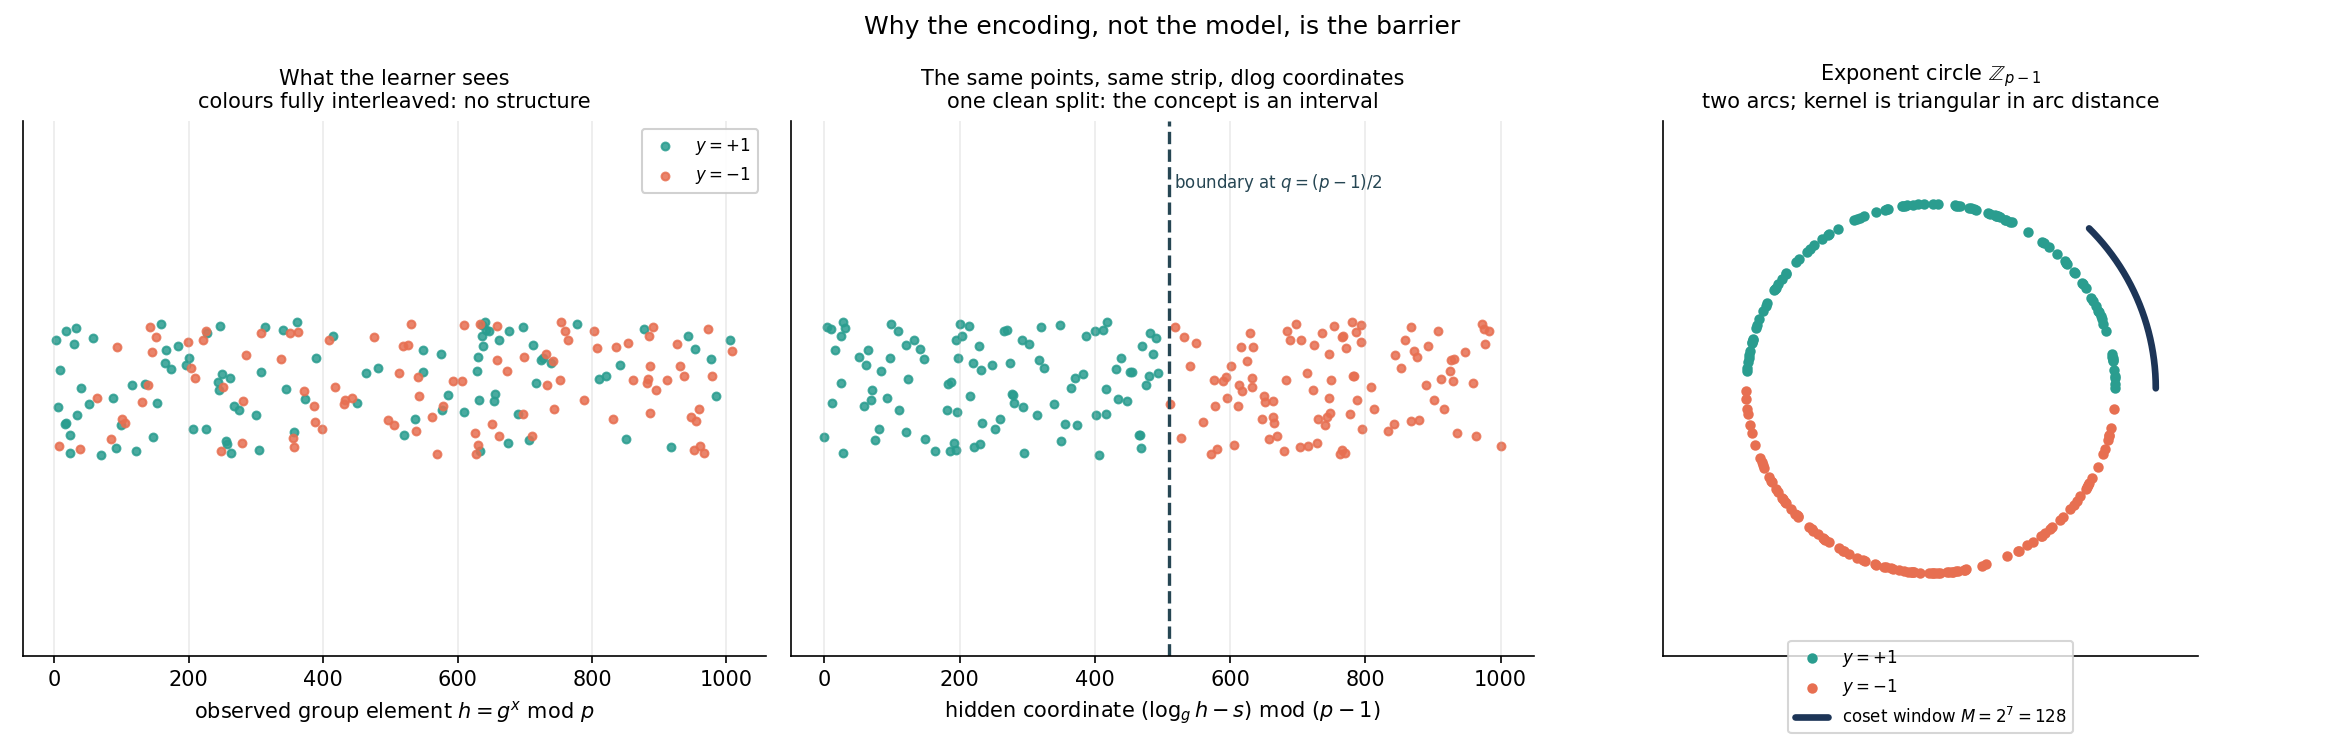

In [7]:
from dlog_qml.plotting import plot_concept_geometry
from dlog_qml.experiments import run_single_experiment
from IPython.display import Image, display

# The reference run is always recomputed, so the headline is never just asserted.
print("running the reference experiment (~30 s) ...")
run = run_single_experiment(cfg, verify=True, keep_kernels=True)
print(f"done in {run['wall_clock_seconds']} s")

display(Image(filename=plot_concept_geometry(run, FIGURES)))

Left is what a model receives: colours interleaved, no visible structure. Middle is the
identical set of points against $(\log_g h - s)\bmod(p-1)$, and the classes fall either
side of one boundary. Right puts it on the exponent circle, with the window $M$ that the
coset feature map will span drawn outside it.

A picture is not evidence of hardness. It is here because it makes the rest of the notebook
easier to follow.

## Classical baselines

Eleven models on the same splits. The tuned RBF-SVM gets a 5-fold CV grid over
$C \in \{0.1,1,10,100,1000\}$ and $\gamma \in \{\text{scale},0.01,0.1,1,10\}$; nothing is
selected on the test split.

One number to keep in mind while reading the table: with $n_{\text{test}} = 50$, the
binomial standard error at chance is $1/(2\sqrt{50}) = 0.0707$. A score of 0.62 is 1.7
standard errors from chance. That is why every row carries an interval and a p-value
instead of just an accuracy.

In [8]:
from dlog_qml.experiments import COSET_KEY, LADDER_KEY, LEGENDRE_KEY, ORACLE_KEY

def results_table(summaries, names, sort=True):
    rows = [{
        "model": n,
        "accuracy": round(summaries[n]["accuracy"], 3),
        "95% CI": f"[{summaries[n]['ci_low']:.3f}, {summaries[n]['ci_high']:.3f}]",
        "p vs chance": (f"{summaries[n]['p_value']:.1e}" if summaries[n]["p_value"] < 1e-4
                        else f"{summaries[n]['p_value']:.3f}"),
        "above chance (p<0.01)": "yes" if summaries[n]["significant_at_1pct"] else "no",
    } for n in names]
    frame = pd.DataFrame(rows)
    return (frame.sort_values("accuracy", ascending=False).reset_index(drop=True)
            if sort else frame)

summaries = run["summaries"]
classical_names = list(run["classical"])
display(results_table(summaries, classical_names))
print(f"{sum(summaries[n]['significant_at_1pct'] for n in classical_names)}"
      f" of {len(classical_names)} classical models clear p < 0.01")

,model,accuracy,95% CI,p vs chance,above chance (p<0.01)
0,Linear-SVM,0.62,"[0.482, 0.741]",0.119,no
1,RBF-SVM (tuned),0.60,"[0.462, 0.724]",0.203,no
2,Poly-SVM (d=3),0.58,"[0.442, 0.706]",0.322,no
3,MLP,0.52,"[0.385, 0.652]",0.888,no
4,RBF-SVM,0.50,"[0.366, 0.634]",1.000,no
5,ExtraTrees,0.50,"[0.366, 0.634]",1.000,no
6,kNN (k=5),0.48,"[0.348, 0.615]",0.888,no
7,GradientBoosting,0.46,"[0.330, 0.596]",0.672,no
8,RandomForest,0.42,"[0.294, 0.558]",0.322,no


0 of 9 classical models clear p < 0.01


None of them. The spread across models is roughly what you would get from eleven coins.

## The generic quantum control

We included this because without it the headline is unfalsifiable. If a generic quantum
kernel also solved the task, the story would be "quantum kernels are good at this", and the
structure argument would be doing no work.

The map is a Havlíček-style second-order encoding with the $R_z$/$R_x$/CZ ladder: per
repetition, $H^{\otimes n}$, then $R_z(2\phi_j)$, a $\mathrm{CX}\cdot R_z \cdot \mathrm{CX}$
$ZZ$ ladder, then $R_x(2\phi_j)$, then a CZ ladder, with $\phi_j = \tfrac{\pi}{2}b_j$. It
entangles across the register and kernels of this family are not known to be classically
simulable, so it is not a weak opponent.

(The $\pi/2$ scale is deliberate. With $\phi = \pi b$, $R_z(2\phi)$ is a global phase and the
single-qubit layer quietly becomes the identity — that would turn the control into a straw
man. There is a test pinning it.)

In [9]:
from dlog_qml.quantum_generic import LadderFeatureMap

ladder = LadderFeatureMap(group.n_bits, reps=cfg.ladder_reps)
info = ladder.describe()
print(f"{info['n_qubits']} qubits, {info['reps']} reps, depth {info['depth']}, "
      f"{info['n_gates']} gates")
print(info["gate_counts"])
print()
print(ladder.circuit(data.features("train")[0].astype(int)).draw(
    output="text", fold=94, initial_state=False))

10 qubits, 2 reps, depth 64, 133 gates
{'rz': 38, 'cx': 36, 'h': 20, 'rx': 20, 'cz': 18, 'barrier': 1}

     ┌───┐┌───────┐                   ┌───────┐                                          »
q_0: ┤ H ├┤ Rz(π) ├──■─────────────■──┤ Rx(π) ├────────────────────────────────■─────────»
     ├───┤├───────┤┌─┴─┐┌───────┐┌─┴─┐└───────┘                   ┌───────┐    │         »
q_1: ┤ H ├┤ Rz(0) ├┤ X ├┤ Rz(0) ├┤ X ├────■────────────────────■──┤ Rx(0) ├────■─────────»
     ├───┤├───────┤└───┘└───────┘└───┘  ┌─┴─┐  ┌────────────┐┌─┴─┐└───────┘              »
q_2: ┤ H ├┤ Rz(0) ├─────────────────────┤ X ├──┤ Rz(4.9348) ├┤ X ├────■───────────────■──»
     ├───┤├───────┤                     └───┘  └────────────┘└───┘  ┌─┴─┐  ┌───────┐┌─┴─┐»
q_3: ┤ H ├┤ Rz(π) ├─────────────────────────────────────────────────┤ X ├──┤ Rz(0) ├┤ X ├»
     ├───┤├───────┤                                                 └───┘  └───────┘└───┘»
q_4: ┤ H ├┤ Rz(0) ├──────────────────────────────────────────────────────────

## The structure-aware kernel

Instead of encoding the bits of $h$, encode a stretch of the group's own orbit:

$$|\Phi(h)\rangle = \frac{1}{\sqrt{M}}\sum_{i=0}^{M-1}\big|\,h\cdot g^{i} \bmod p\,\big\rangle,
\qquad M = 2^{m}.$$

Constructing that state uses forward modular multiplication only. It never calls a discrete
logarithm, which matters — the feature map has to be buildable by someone without the
trapdoor, or the whole setup is circular.

The kernel follows from geometry. With $a=\log_g h$, $a'=\log_g h'$, $N=p-1$ and
$\delta=(a'-a)\bmod N$, the two supports are length-$M$ arithmetic progressions on the
circle $\mathbb{Z}_N$, so they intersect in

$$\Omega(\delta) = \max(0, M-\delta) + \max(0, M-(N-\delta))$$

elements (forward plus wraparound; for $2M \le N$ only one term can be positive). Uniform
real amplitudes $1/\sqrt{M}$ then give

$$K(h,h') = \left(\frac{\Omega(\delta)}{M}\right)^{2}.$$

A triangular kernel in discrete-log distance. The state performs the coordinate change
implicitly and the SVM is left with interval membership in one dimension.

Worth being precise about what this is not: preparing $|\Phi(h)\rangle$ densely, as we do in
simulation, costs $\Theta(2^n)$. That is a simulation mechanism for studying the geometry.
The efficient construction is Shor-style period finding at $O(n^3)$ gates, which we cite
and did not implement.

In [10]:
from dlog_qml.quantum_coset import CosetStateFeatureMap

coset = CosetStateFeatureMap(group, cfg.window_bits)
d = coset.describe()
print(f"window M = 2^{d['window_bits']} = {d['window_M']} of |Z_p*| = {d['group_order']} "
      f"({d['window_fraction_of_group']:.1%} of the group)")
print()

# Three independent routes to the same Gram matrix.
v_c, v_g = run["quantum_coset"]["verification"], run["quantum_generic"]["verification"]
print("kernel checks (max abs difference)")
print(f"  coset   vs compute-uncompute circuits   {v_c['max_compute_uncompute_error']:.1e}")
print(f"  coset   vs closed-form triangle formula {v_c['max_analytic_error']:.1e}")
print(f"  generic vs compute-uncompute circuits   {v_g['max_compute_uncompute_error']:.1e}")
props = run["quantum_coset"]["kernel_properties"]
print(f"  symmetric {props['symmetric']}, unit diagonal {props['unit_diagonal']}, "
      f"PSD {props['positive_semidefinite']}")

window M = 2^7 = 128 of |Z_p*| = 1018 (12.6% of the group)

kernel checks (max abs difference)
  coset   vs compute-uncompute circuits   3.0e-13
  coset   vs closed-form triangle formula 4.4e-16
  generic vs compute-uncompute circuits   1.7e-18
  symmetric True, unit diagonal True, PSD True


## Main result

Identical splits, identical Gram-matrix machinery, identical model selection. The only
thing that changes between the two quantum rows is the feature map.

In [11]:
display(results_table(summaries, classical_names + [LADDER_KEY, COSET_KEY]))

print(f"best competitor  {run['best_competitor']}  {run['best_competitor_accuracy']:.3f}")
print(f"coset kernel     {run['coset_accuracy']:.3f}")
print(f"separation       {run['separation']:+.3f}")
print(f"any competitor above chance at p<0.01: "
      f"{'YES' if run['any_competitor_significant_at_1pct'] else 'no'}")

,model,accuracy,95% CI,p vs chance,above chance (p<0.01)
0,Quantum coset kernel,0.94,"[0.838, 0.979]",3.7e-11,yes
1,Linear-SVM,0.62,"[0.482, 0.741]",0.119,no
2,RBF-SVM (tuned),0.60,"[0.462, 0.724]",0.203,no
3,Quantum generic kernel,0.60,"[0.462, 0.724]",0.203,no
4,Poly-SVM (d=3),0.58,"[0.442, 0.706]",0.322,no
5,MLP,0.52,"[0.385, 0.652]",0.888,no
6,RBF-SVM,0.50,"[0.366, 0.634]",1.000,no
7,ExtraTrees,0.50,"[0.366, 0.634]",1.000,no
8,kNN (k=5),0.48,"[0.348, 0.615]",0.888,no
9,GradientBoosting,0.46,"[0.330, 0.596]",0.672,no


best competitor  Linear-SVM  0.620
coset kernel     0.940
separation       +0.320
any competitor above chance at p<0.01: no


In [12]:
def bar(v, width=34):
    f = int(round(width * v)); return "#" * f + "." * (width - f)

def show_bars(title, entries):
    print(title); print()
    for label, v in entries:
        print(f"  {label:<17} {bar(v)} {v*100:5.1f}%")

show_bars(f"single reference run (seed {cfg.seed}, n_test={cfg.n_test})",
          [("coset quantum", run["coset_accuracy"]),
           ("best classical", run["best_competitor_accuracy"]),
           ("generic quantum", summaries[LADDER_KEY]["accuracy"]),
           ("chance", 0.50)])
print()
print("  One 50-item test set is a weak instrument. The seed sweep below is")
print("  the number to trust.")

single reference run (seed 20260828, n_test=50)

  coset quantum     ################################..  94.0%
  best classical    #####################.............  62.0%
  generic quantum   ####################..............  60.0%
  chance            #################.................  50.0%

  One 50-item test set is a weak instrument. The seed sweep below is
  the number to trust.


# Try to disprove the result

Four controls. Each one is a way the headline could have been wrong, and each was run
rather than argued about.

### First: is there any signal in the data?

Before anything quantum, the boring failure mode. If the labels were noise, every model
would sit at 50% and we would have "discovered" nothing. So: hand a RandomForest the hidden
exponent directly and see whether the target is learnable at all when the coordinate is
available.

This is not a baseline. It holds the trapdoor.

In [13]:
oracle = run["oracle_control"]
print(f"RandomForest on the hidden exponent x: {oracle['test_accuracy']:.3f}  "
      f"(p = {summaries[ORACLE_KEY]['p_value']:.1e})")
print(f"same model on the public bits:         "
      f"{run['classical']['RandomForest']['test_accuracy']:.3f}")

RandomForest on the hidden exponent x: 0.960  (p = 2.3e-12)
same model on the public bits:         0.420


So the labels are a clean function of the hidden coordinate. Whatever is stopping the other
models, it is not label noise.

### Second: is the target actually hidden?

Our first version of this dataset labelled by the parity of the discrete log,
$y = (-1)^{\log_g h \bmod 2}$. That was a bad target, and finding out why is probably the
most useful thing in this notebook.

The low bit of a discrete log in $\mathbb{Z}_p^*$ is directly exposed by quadratic
residuosity, and Euler's criterion reads it off in $O(\log p)$:

$$h^{(p-1)/2} \bmod p = 1 \iff h \text{ is a QR} \iff \log_g h \text{ is even}.$$

The hardcore bits of a discrete log are the high-order ones (Blum–Micali); the low one is
free. So we kept parity as a control and moved the main experiment to the half-interval
target. Below we check the equivalence on every element of the group, then run the attack
against both targets.

In [14]:
from dlog_qml.labels import legendre_predict

h_all = np.arange(1, group.p)
same = np.array_equal(legendre_predict(group, h_all),
                      np.array([1 if group.dlog(int(h)) % 2 == 0 else -1 for h in h_all]))
print(f"Euler's criterion == dlog parity, checked on all {len(h_all)} elements: {same}")

parity_data = generate_dataset(n_qubits=cfg.n_qubits, n_train=cfg.n_train,
                               n_test=cfg.n_test, seed=cfg.seed, labeling="parity")
on_parity = (legendre_predict(parity_data.group, parity_data.group_elements("test"))
             == parity_data.labels("test")).mean()
on_target = run["legendre_control"]["test_accuracy"]
print()
print(f"  attack on the parity target      {on_parity:.3f}")
print(f"  attack on the half-interval one  {on_target:.3f}")

Euler's criterion == dlog parity, checked on all 1018 elements: True

  attack on the parity target      1.000
  attack on the half-interval one  0.460


An $O(\log p)$ classical routine solves the parity version outright and does nothing against
the target we use. We are not relying on "it involves a discrete logarithm, therefore it is
hard" — we know what a broken version of our own construction looks like because we built
one.

### Third: does the coset kernel work on anything?

The obvious worry about a hand-designed feature map is that it is a general-purpose cheat.
Easy to test: run it on the parity target, which is a different concept over the same group.

In [15]:
from dlog_qml.artifacts import run_or_load, require

parity_run, prov_par = run_or_load(
    "parity_run", os.path.join(RAW, "parity_run.json"),
    lambda: run_single_experiment(cfg.replace(labeling="parity"), verify=False),
    prefer_cached=not RUN_FRESH_EXPERIMENT)
parity_run = require(parity_run, prov_par, "run: python scripts/run_experiment.py")
print(prov_par.banner()); print()
print(f"  coset kernel on the half-interval target  {run['coset_accuracy']:.3f}")
print(f"  coset kernel on the parity target         {parity_run['coset_accuracy']:.3f}")

[CACHED ARTIFACT]  parity_run  (loaded from disk, written 2026-08-28 22:12:56)

  coset kernel on the half-interval target  0.940
  coset kernel on the parity target         0.460


It fails. The triangular kernel is local on the dlog circle and parity alternates at every
step, so a local kernel is close to the worst possible choice for it. The feature map helps
when its geometry lines up with the target and not otherwise — which is the claim we wanted
to make, stated as a limitation rather than a boast.

### Fourth: is it just "quantum"?

Covered by the main table above, but it belongs in this list. The generic quantum kernel
runs through the same pipeline and lands with the classical models. Whatever produces the
gap, it is not the presence of a quantum kernel.

## What changes across seeds

One split is not much evidence. Each seed here redraws the secret shift *and* the sample
set, so this varies the concept as well as the data.

In [16]:
from dlog_qml.experiments import run_multi_seed

multi_seed, prov_ms = run_or_load(
    "multi_seed", os.path.join(RAW, "multi_seed.json"),
    lambda: run_multi_seed(cfg, progress=False),
    prefer_cached=not RUN_FRESH_EXPERIMENT)
multi_seed = require(multi_seed, prov_ms, "run: python scripts/run_experiment.py")
print(prov_ms.banner()); print()

per = multi_seed["per_model"]
frame = pd.DataFrame([{"model": n, "mean": round(v["mean"], 3), "std": round(v["std"], 3),
                       "median": round(v["median"], 3), "min": round(v["min"], 3),
                       "max": round(v["max"], 3), "seeds": v["n_runs"]}
                      for n, v in sorted(per.items(), key=lambda kv: -kv[1]["mean"])])
display(frame)

[CACHED ARTIFACT]  multi_seed  (loaded from disk, written 2026-08-28 22:15:07)



,model,mean,std,median,min,max,seeds
0,Hidden-x oracle (control),0.992,0.015,1.00,0.96,1.00,20
1,Quantum coset kernel,0.989,0.018,1.00,0.94,1.00,20
2,Poly-SVM (d=3),0.541,0.070,0.52,0.44,0.64,20
3,ExtraTrees,0.541,0.082,0.54,0.40,0.64,20
4,RBF-SVM (tuned),0.537,0.095,0.54,0.34,0.68,20
5,RandomForest,0.526,0.098,0.54,0.40,0.68,20
6,Linear-SVM,0.524,0.084,0.53,0.36,0.70,20
7,kNN (k=5),0.515,0.078,0.48,0.40,0.70,20
8,RBF-SVM,0.515,0.090,0.51,0.36,0.74,20
9,Quantum generic kernel,0.503,0.078,0.51,0.34,0.62,20


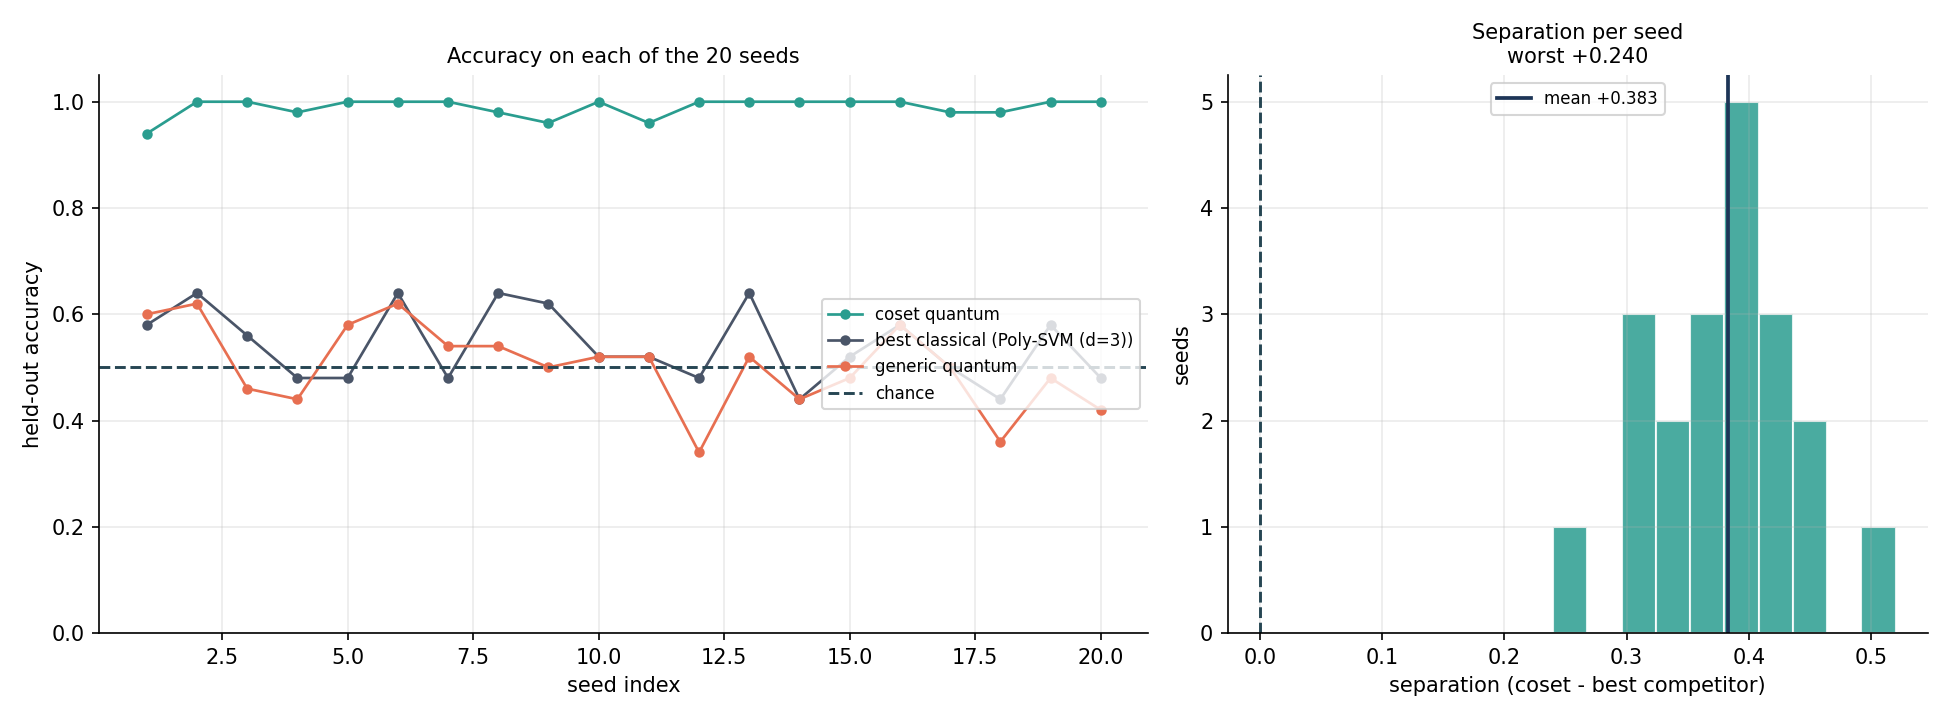

In [17]:
from dlog_qml.plotting import plot_seed_distribution
display(Image(filename=plot_seed_distribution(multi_seed, FIGURES)))

The per-seed view matters more than the summary statistics: the coset kernel is above every
other model on every seed, and the separation histogram has no mass near zero. If the effect
were driven by a few lucky splits it would show up here as overlap, and it does not.

## Where the headline numbers come from

There are two defensible ways to quote the separation and they give different answers, so
it is worth being explicit rather than picking the flattering one.

- **Per-seed:** on each seed, take the best competitor *on that seed* and subtract. Averaging
  those gives the more conservative figure, because the comparison target is a per-seed
  maximum.
- **Pooled:** take the coset mean minus the mean of the single best-performing competitor
  across all seeds.

We quote the per-seed number. Below, both are recomputed from the raw per-seed accuracies
rather than read from any summary field, and a few other headline values are re-derived
independently to check they agree.

In [18]:
from dlog_qml.audit import headline_numbers, check_consistency

numbers = headline_numbers(run, multi_seed=multi_seed, parity=parity_run)
ms = numbers["multi_seed"]

print(f"per-seed separation (quoted)  {ms['separation_mean']:+.3f} "
      f"+/- {ms['separation_std']:.3f}   worst seed {ms['separation_min']:+.3f}")
print(f"pooled gap                    {ms['headline_gap']:+.3f}   "
      f"(coset mean - {ms['best_competitor']} mean)")
print(f"seeds where coset > best competitor: "
      f"{ms['seeds_coset_beats_best']}/{ms['n_seeds']}")
print()
display(pd.DataFrame(check_consistency(numbers, run, multi_seed)))

per-seed separation (quoted)  +0.383 +/- 0.062   worst seed +0.240
pooled gap                    +0.448   (coset mean - Poly-SVM (d=3) mean)
seeds where coset > best competitor: 20/20



,quantity,quoted,recomputed,agrees
0,reference separation,0.320,0.320,True
1,coset accuracy,0.940,0.940,True
2,coset accuracy (from confusion matrix),0.940,0.940,True
3,best competitor accuracy,0.620,0.620,True
4,coset mean over seeds,0.989,0.989,True
5,generic mean over seeds,0.503,0.503,True
6,separation mean over seeds,0.383,0.383,True
7,n seeds,20.000,20.000,True


## Statistics

Two accuracies side by side do not answer "is A better than B" — they are two separate
one-sample statements. A paired test on the same held-out items does answer it, so that is
what we use for the model comparison.

- **Exact binomial**, per model: is this classifier distinguishable from chance on this test
  set? Exact rather than normal-approximate because $n = 50$.
- **Wilson interval**: coverage interval for the accuracy, behaves properly near 0 and 1
  where our quantum results sit.
- **McNemar, exact**: do the two classifiers have different error rates on the *same* items?
  Exact binomial form, since our discordant counts are in the tens and $\chi^2$ is
  anti-conservative there.
- **Paired bootstrap**: interval for the accuracy difference, resampling test items with the
  same index set applied to both models.

In [19]:
mc = run["paired_test"]["mcnemar"]
bs = run["paired_test"]["bootstrap_accuracy_difference"]
print(run["paired_test"]["comparison"])
print(f"  coset right / other wrong   {mc['n_a_correct_b_wrong']}")
print(f"  coset wrong / other right   {mc['n_a_wrong_b_correct']}")
print(f"  McNemar exact p             {mc['p_value']:.1e}")
print(f"  bootstrap difference        {bs['difference']:+.3f}  "
      f"95% CI [{bs['ci_low']:+.3f}, {bs['ci_high']:+.3f}]")

Quantum coset kernel vs Linear-SVM
  coset right / other wrong   19
  coset wrong / other right   3
  McNemar exact p             8.6e-04
  bootstrap difference        +0.320  95% CI [+0.160, +0.480]


On the p-value, since this is the number most likely to be over-read. It says: under the
null that this classifier is at chance on this test set, a result this extreme is very
unlikely. Nothing more. Three things it is not:

| | |
|---|---|
| statistical significance | this model is not guessing — **measured here** |
| computational advantage | no efficient classical algorithm exists — **not measured here** |
| quantum speedup | requires the asymptotic argument and hardware — **not shown here** |

The second line is a conditional theorem in the literature, not something a p-value on 50
samples can establish.

## Ablation

The window $M = 2^m$ is the one free parameter in the coset map. It is set by a fixed rule
($M \approx (p-1)/8$) rather than tuned, but "we did not tune it" is not the same as "it does
not matter", so we swept the whole valid range.

In [20]:
from dlog_qml.experiments import run_window_ablation, build_ablation_table

ablation, prov_ab = run_or_load(
    "window_ablation", os.path.join(RAW, "window_ablation.json"),
    lambda: run_window_ablation(cfg, progress=False),
    prefer_cached=not RUN_FRESH_EXPERIMENT)
ablation = require(ablation, prov_ab, "run: python scripts/run_experiment.py")
print(prov_ab.banner()); print()

table = pd.DataFrame(build_ablation_table(run, ablation=ablation, parity=parity_run))
table["accuracy"] = table["accuracy"].round(3)
table["delta_vs_full"] = table["delta_vs_full"].round(3)
display(table[["component", "variant", "accuracy", "delta_vs_full", "question"]])

[CACHED ARTIFACT]  window_ablation  (loaded from disk, written 2026-08-28 22:16:14)



,component,variant,accuracy,delta_vs_full,question
0,Full system,"coset kernel, default window",0.94,0.00,reference configuration
1,Representation,generic Rz/Rx/CZ feature map,0.60,-0.34,Would any expressive quantum feature map do?
2,Representation,best classical (Linear-SVM),0.62,-0.32,Is a classical kernel on the same bits enough?
3,Coset window,m=1 (M=2),0.74,-0.20,Does the result hinge on a tuned window size?
4,Coset window,m=2 (M=4),0.88,-0.06,Does the result hinge on a tuned window size?
5,Coset window,m=3 (M=8),0.98,0.04,Does the result hinge on a tuned window size?
6,Coset window,m=4 (M=16),0.96,0.02,Does the result hinge on a tuned window size?
7,Coset window,m=5 (M=32),0.94,0.00,Does the result hinge on a tuned window size?
8,Coset window,m=6 (M=64),0.94,0.00,Does the result hinge on a tuned window size?
9,Coset window,m=7 (M=128),0.94,0.00,Does the result hinge on a tuned window size?


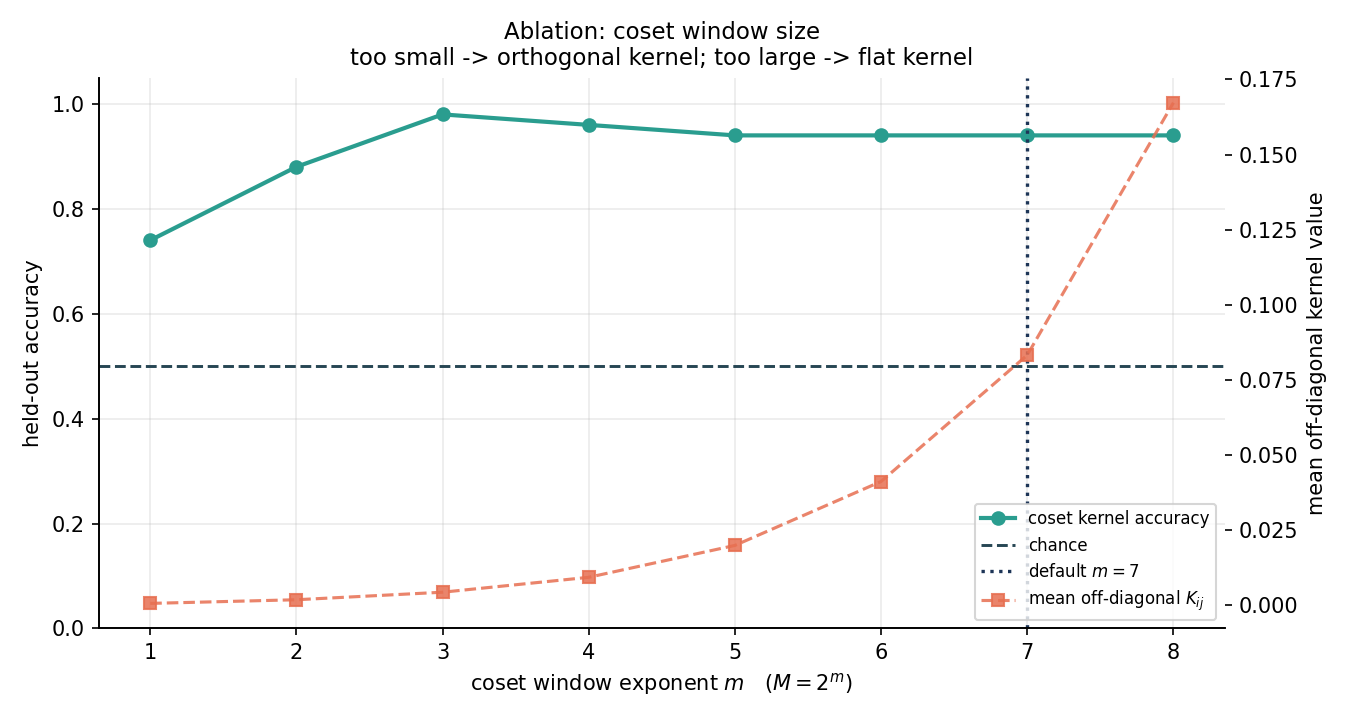

In [21]:
from dlog_qml.plotting import plot_window_ablation
display(Image(filename=plot_window_ablation(ablation, FIGURES)))

Accuracy holds up from $m=2$ to $m=8$; only $m=1$, a two-element window that makes almost
every pair orthogonal, drops off. The default is not the best value in the range, which is
mildly reassuring — it means the number in the headline is not the product of a search.

Two things this does *not* establish: we only tested windows satisfying $2M \le N$, and the
sweep is single-seed, so the individual points carry the same 7-point standard error as
everything else at $n=50$.

## Looking at the kernel itself

The generic kernel landing at chance was not surprising. What we wanted was a reason, so we
looked at the Gram matrices rather than stopping at the accuracy.

Sorting the training points by their hidden $\log_g h$ — the coordinate no model has access
to — makes the difference visible immediately.

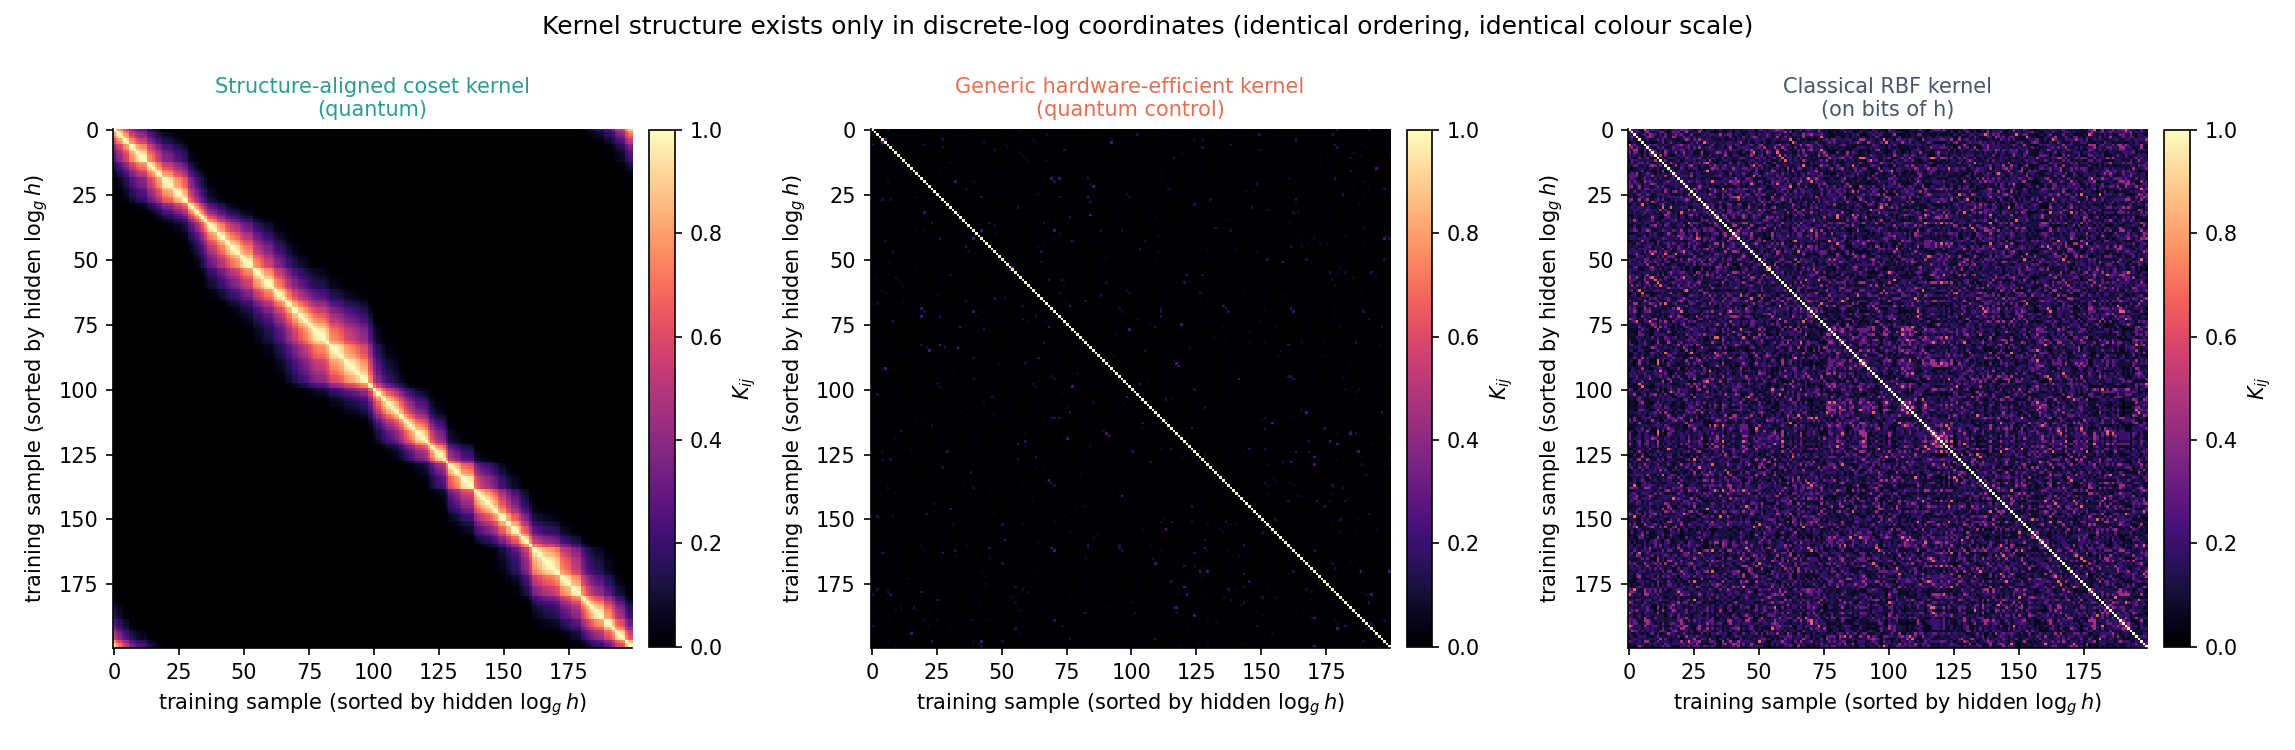

In [22]:
from dlog_qml.plotting import plot_kernel_matrices
display(Image(filename=plot_kernel_matrices(run, FIGURES)))

Same ordering and same colour scale in all three panels. The coset kernel is a band whose
width is the coset window, with corners from the wraparound — which is what the closed form
predicts. The generic kernel is essentially the identity. The classical RBF kernel has
plenty of variance but none of it organised along the dlog axis.

Three quantities make that precise:

- **kernel-target alignment**, $\langle K, yy^{\mathsf T}\rangle_F / (\|K\|_F\|yy^{\mathsf T}\|_F)$,
  computed on the centred kernel so a constant offset cannot inflate it. How much of the
  geometry points along the labels, with no classifier involved.
- **class-conditional similarity**: mean $K_{ij}$ for same-class versus different-class pairs.
- **effective rank** and the eigenspectrum: how many directions the kernel actually uses.

In [23]:
k = numbers["kernel"]
display(pd.DataFrame([
    {"": "mean off-diagonal K",  "coset": k["coset"]["offdiag_mean"],
     "generic": k["generic"]["offdiag_mean"]},
    {"": "effective rank",       "coset": k["coset"]["effective_rank"],
     "generic": k["generic"]["effective_rank"]},
    {"": "top-10 eigenvalue mass", "coset": k["coset"]["top10_fraction"],
     "generic": k["generic"]["top10_fraction"]},
    {"": "target alignment",     "coset": k["coset"]["alignment"],
     "generic": k["generic"]["alignment"]},
    {"": "K same class",         "coset": k["coset"]["within_class"],
     "generic": k["generic"]["within_class"]},
    {"": "K different class",    "coset": k["coset"]["between_class"],
     "generic": k["generic"]["between_class"]},
    {"": "separation gap",       "coset": k["coset"]["separation_gap"],
     "generic": k["generic"]["separation_gap"]},
]).round(5))
print(f"training-set size n = {k['coset']['n']}")

,,coset,generic
0,mean off-diagonal K,0.08319,0.00322
1,effective rank,30.10945,195.26725
2,top-10 eigenvalue mass,0.67986,0.07928
3,target alignment,0.38177,0.07040
4,K same class,0.16138,0.00330
5,K different class,0.00579,0.00314
6,separation gap,0.15559,0.00016


training-set size n = 200


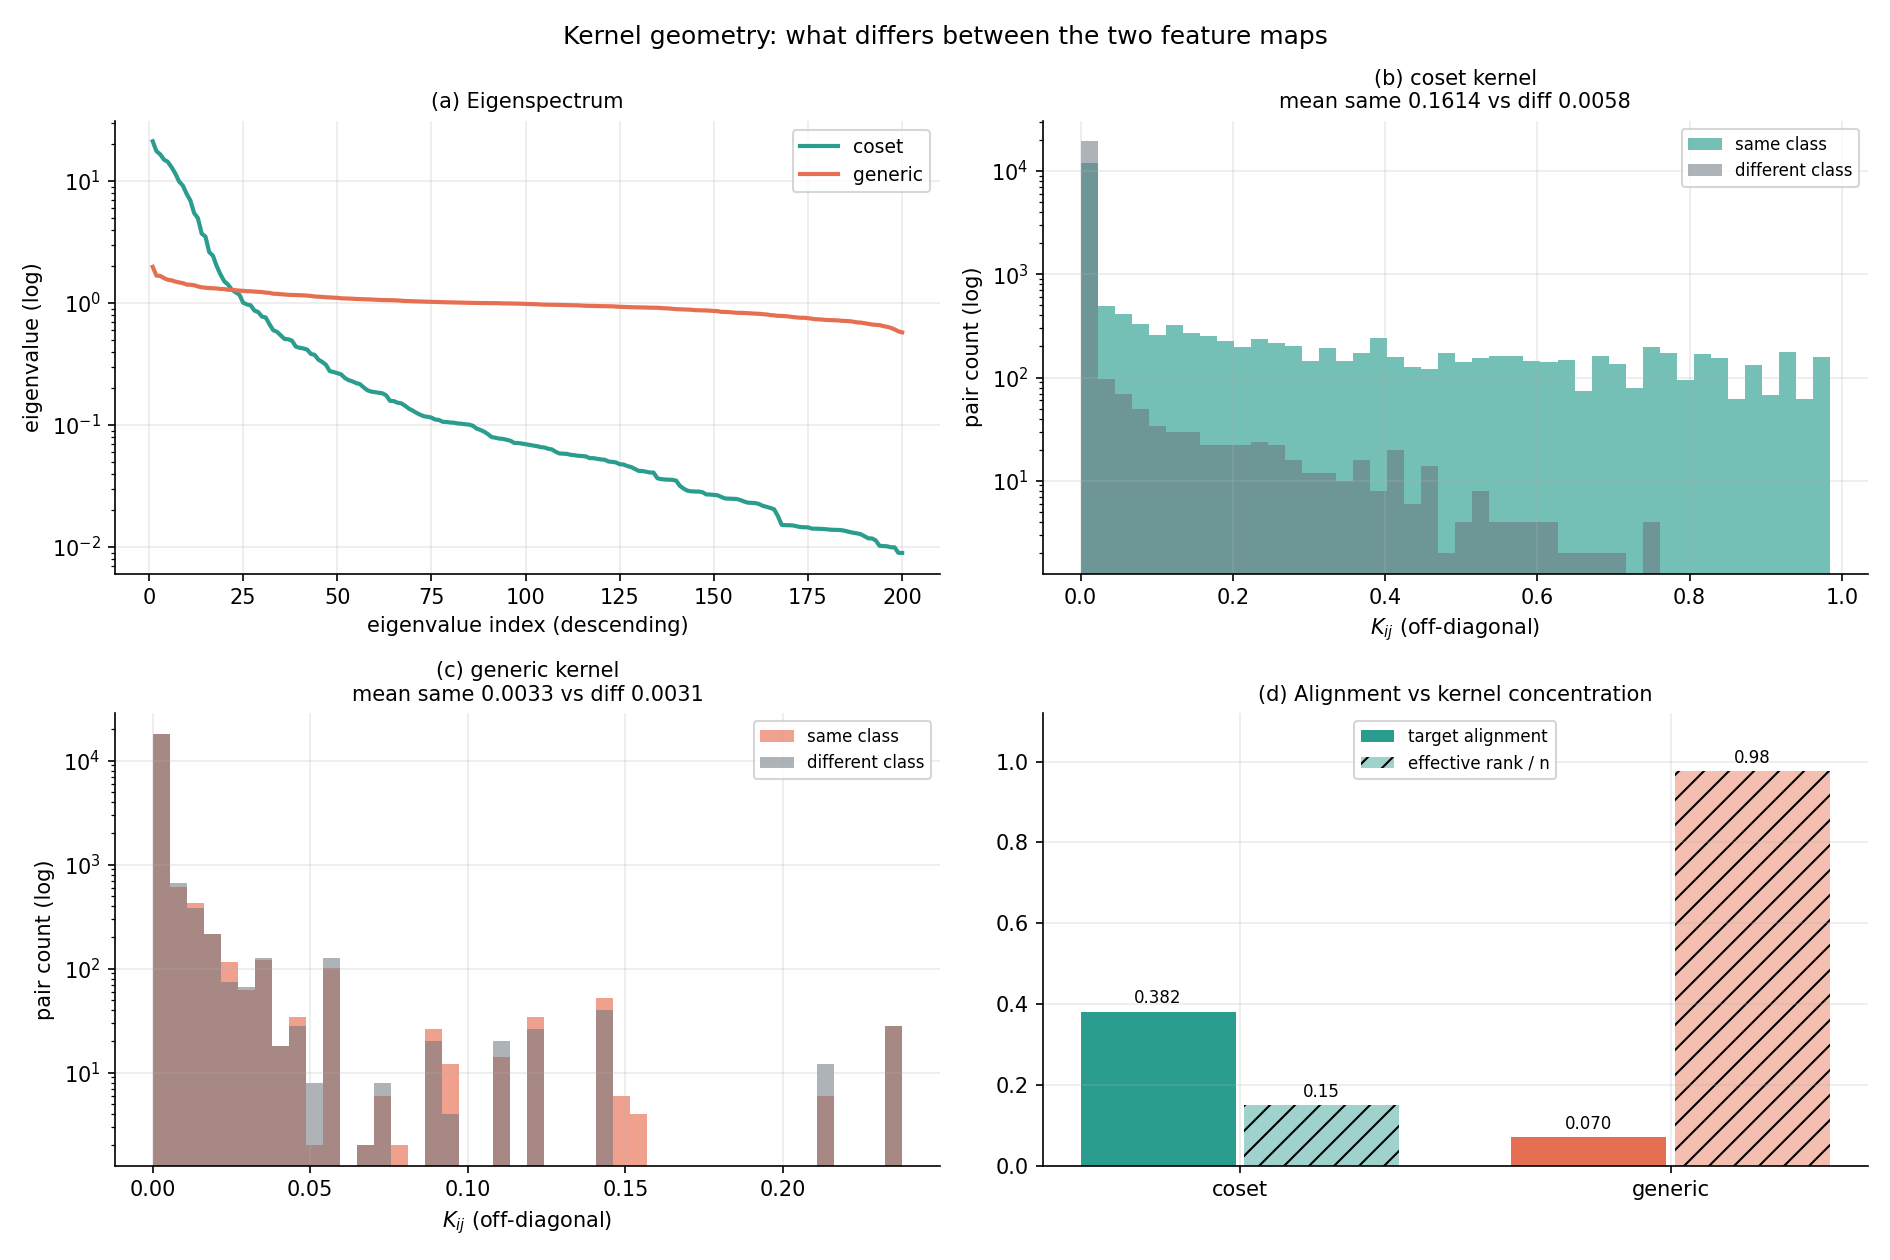

In [24]:
from dlog_qml.plotting import plot_kernel_diagnostics
display(Image(filename=plot_kernel_diagnostics(run, FIGURES)))

Panel (a): the generic kernel's spectrum is nearly flat, so its 200 training points occupy
roughly 195 near-orthogonal directions.

Panels (b) and (c) are the ones we find most useful, though they need reading carefully.
Both kernels put most pairs near zero — that is expected, since the coset kernel is local
and most pairs are far apart on the circle. The difference is in the tail: for the coset
kernel only same-class pairs reach high similarity, and the tail runs all the way to
$K \approx 1$. For the generic kernel the two histograms sit on top of each other across the
whole range, and the means differ by 0.0002.

That is a coherent story: a kernel with no class structure and near-full effective rank can
fit the training set exactly (it does, with every point a support vector) and has nothing
left to generalise with.

We would rather call this consistent with kernel concentration than call it a complete
mechanistic explanation. It tells us what the geometry looks like; it does not prove that
concentration is the only reason the accuracy is what it is.

## Scaling of the simulation

These are measurements from real runs at each register width — accuracy, wall-clock, and
statevector memory. They describe our simulation, not a quantum computer.

In [25]:
from dlog_qml.experiments import run_size_sweep

sweep, prov_sw = run_or_load(
    "size_sweep", os.path.join(RAW, "size_sweep.json"),
    lambda: run_size_sweep(cfg, progress=False),
    prefer_cached=not RUN_FRESH_EXPERIMENT)
sweep = require(sweep, prov_sw, "run: python scripts/run_experiment.py")
print(prov_sw.banner()); print()

good = [r for r in sweep["rows"] if "error" not in r]
display(pd.DataFrame(good)[["n_qubits", "p", "n_train", "n_test", "coset_accuracy",
                            "generic_accuracy", "best_competitor_accuracy",
                            "coset_simulate_seconds", "statevector_megabytes"]].round(3))

[CACHED ARTIFACT]  size_sweep  (loaded from disk, written 2026-08-28 22:15:28)



,n_qubits,p,n_train,n_test,coset_accuracy,generic_accuracy,best_competitor_accuracy,coset_simulate_seconds,statevector_megabytes
0,6,59,48,10,1.000,0.600,0.700,0.000,0.057
1,7,107,86,20,0.950,0.450,0.500,0.002,0.207
2,8,227,182,44,0.977,0.386,0.614,0.003,0.883
3,9,503,200,50,1.000,0.460,0.460,0.007,1.953
4,10,1019,200,50,0.940,0.600,0.600,0.018,3.906


Memory doubles with each qubit, which is the wall that keeps this a small experiment. Read
the accuracy column with care: at $n=6$ there are 12 test points, so those rows have very
wide intervals and are not a trend.

Nothing here says anything about how a quantum implementation would scale. The dense state
preparation we simulate is exponential; the $O(n^3)$ construction is Shor's and we did not
build it.

## Controls, collected

Each row states the observation and what would have invalidated the result.

In [26]:
from dlog_qml.experiments import negative_controls_checklist

controls = negative_controls_checklist(run, parity=parity_run,
                                       multi_seed=multi_seed, ablation=ablation)
display(pd.DataFrame(controls)[["control", "observed", "passed", "would_invalidate_if"]])
print(f"{sum(c['passed'] for c in controls)}/{len(controls)} passed")

,control,observed,passed,would_invalidate_if
0,Hidden-x oracle succeeds,0.960,True,labels are noise or the generator is broken
1,Generic quantum kernel fails,0.600 (p=0.203),True,"the effect is 'quantum', not 'structure-aware'"
2,Legendre attack fails on target,0.460,True,a poly-time classical shortcut explains the label
3,No competitor beats chance,none,True,the concept is classically learnable by a test...
4,Train/test exponents disjoint,True,True,the gap could be memorisation
5,Exact class balance,"train {'positive': 100, 'negative': 100}, test...",True,chance level would not be 0.5
6,Kernel equals circuit definition,"3.0e-13 (circuits), 4.4e-16 (closed form)",True,the simulated kernel is not the fidelity kernel
7,Coset kernel fails on parity,0.460,True,"the quantum kernel is a universal cheat, not s..."
8,Legendre attack breaks parity,1.000,True,our falsification tool does not actually work
9,Separation holds across seeds,min +0.240 over 20 seeds,True,the result is one lucky seed


11/11 passed


## What the experiment does and does not show

| We establish | We do not establish |
|---|---|
| A large, repeatable accuracy gap on this task under the tested conditions | That no efficient classical algorithm exists for it |
| A generic quantum kernel does not close that gap | That quantum kernels are generally better |
| The target is not exposed by the obvious number-theoretic invariant | That the target is cryptographically hard at this size |
| The labels are learnable given the hidden coordinate | Anything about hardware behaviour |
| The coset kernel fails on a target it is not matched to | A complexity-theoretic separation |
| The simulated kernel matches the circuit definition to ~1e-13 | That dense state preparation is efficient |

Specifics worth stating plainly:

- $p = 1019$ is small. Baby-step giant-step solves it, and our own dataset audit does exactly
  that on every run.
- Everything is classical simulation. No hardware results appear anywhere in this repository.
- Dense `StatePreparation` costs $\Theta(2^n)$. It is how we study the geometry, not the
  algorithm one would deploy.
- Eleven baselines failing is evidence, not proof. We did not run a large architecture
  search, and we cannot rule out a method we did not try.
- The asymptotic argument for this concept class is a conditional theorem due to Liu,
  Arunachalam and Temme, resting on the discrete-log assumption. It is theirs, and we did
  not reproduce it.

In [27]:
from dlog_qml.group import baby_step_giant_step
import time

h_probe = int(data.group_elements("test")[0])
t0 = time.perf_counter()
x_solved = baby_step_giant_step(group.g, h_probe, group.p)
dt = time.perf_counter() - t0
print(f"baby-step giant-step: log_g({h_probe}) = {x_solved} in {dt*1000:.2f} ms "
      f"(correct: {pow(group.g, x_solved, group.p) == h_probe})")
print("This instance is classically trivial, which is why the claim is about learning.")

baby-step giant-step: log_g(439) = 659 in 0.14 ms (correct: True)
This instance is classically trivial, which is why the claim is about learning.


## Verified summary

Generated from the artifacts, not typed.

In [28]:
ref = numbers["reference"]
rows = [
    ("hidden-x oracle",              ref["oracle_accuracy"],  "single run"),
    ("Legendre attack, parity target", numbers["parity"]["legendre_accuracy"], "single run"),
    ("Legendre attack, our target",  ref["legendre_accuracy"], "single run"),
    ("coset kernel, parity target",  numbers["parity"]["coset_accuracy"], "single run"),
    ("best classical",               ref["best_competitor_accuracy"],
     f"single run ({ref['best_competitor']})"),
    ("generic quantum kernel",       ref["generic_accuracy"], "single run"),
    ("coset quantum kernel",         ref["coset_accuracy"],   "single run"),
    ("coset kernel",                 ms["coset_mean"],        f"mean of {ms['n_seeds']} seeds"),
    ("generic kernel",               ms["generic_mean"],      f"mean of {ms['n_seeds']} seeds"),
    ("best classical",               ms["best_competitor_mean"],
     f"mean of {ms['n_seeds']} seeds ({ms['best_competitor']})"),
    ("separation (per-seed)",        ms["separation_mean"],   f"mean of {ms['n_seeds']} seeds"),
]
display(pd.DataFrame(rows, columns=["quantity", "value", "source"]).round(4))

print(f"reference coset: {ref['coset_accuracy']:.3f}  "
      f"CI [{ref['coset_ci'][0]:.3f}, {ref['coset_ci'][1]:.3f}]  "
      f"p = {ref['coset_p']:.1e}  AUC = {ref['coset_auc']:.4f}")
print(f"McNemar p = {ref['mcnemar_p']:.1e}   "
      f"bootstrap CI [{ref['bootstrap_ci'][0]:+.3f}, {ref['bootstrap_ci'][1]:+.3f}]")
print(f"controls passed: {sum(c['passed'] for c in controls)}/{len(controls)}")

,quantity,value,source
0,hidden-x oracle,0.960,single run
1,"Legendre attack, parity target",1.000,single run
2,"Legendre attack, our target",0.460,single run
3,"coset kernel, parity target",0.460,single run
4,best classical,0.620,single run (Linear-SVM)
5,generic quantum kernel,0.600,single run
6,coset quantum kernel,0.940,single run
7,coset kernel,0.989,mean of 20 seeds
8,generic kernel,0.503,mean of 20 seeds
9,best classical,0.541,mean of 20 seeds (Poly-SVM (d=3))


reference coset: 0.940  CI [0.838, 0.979]  p = 3.7e-11  AUC = 0.9968
McNemar p = 8.6e-04   bootstrap CI [+0.160, +0.480]
controls passed: 11/11


## Reproducing this

```bash
pip install -r requirements.txt
python -m pytest                    # 187 tests
python scripts/demo.py              # terminal version, ~23 s
python scripts/run_experiment.py    # full study, ~200 s
python scripts/build_notebook.py --execute   # rebuild and run this notebook
```

One seed controls the secret, the sampling and every `random_state`, so the dataset is
reproducible byte-for-byte. The kernels are exact statevector inner products, so there is no
shot noise to average out either.

A couple of things we got wrong along the way and fixed, since they are the kind of thing
that would otherwise sit silently in a result: an empty-run summary returned `NaN` for a
run *count* rather than 0, and the accuracy figure was sorting bars by single-run values
while labelling them with multi-seed means. Both were caught by tests and by reading the
figure. There is also a wrinkle in the `qiskit-machine-learning` cross-check — its
`FidelityQuantumKernel` defaults to `enforce_psd=True`, whose eigenvalue clipping distorts a
matrix that is already exact and PSD (it pushed diagonal entries to 1.0245), so the
comparison needs `enforce_psd=False` to be like-for-like.

In [29]:
from dlog_qml.experiments import environment_info

for key, value in environment_info().items():
    print(f"  {key:<26} {value}")
print()
print("provenance of everything shown above:")
print(f"  reference run              recomputed live, every execution")
for p in (prov_ms, prov_ab, prov_par, prov_sw):
    print(f"  {p.name:<26} {p.source}")

  python                     3.13.14
  platform                   Windows-11-10.0.26200-SP0
  numpy                      2.5.2
  pandas                     2.3.3
  sklearn                    1.9.0
  qiskit                     2.5.1
  qiskit_machine_learning    0.9.0
  scipy                      1.17.1
  matplotlib                 3.10.3

provenance of everything shown above:
  reference run              recomputed live, every execution
  multi_seed                 cached
  window_ablation            cached
  parity_run                 cached
  size_sweep                 cached


## Takeaway

The main result is fairly simple. The generic quantum kernel does not solve this task. The
eleven classical baselines we tested do not either. The structure-aware coset kernel does,
and that difference survives every check we ran: twenty seeds, a window ablation, paired
significance testing, a number-theoretic attack on the target, and a mismatched-concept test
that the quantum kernel fails.

What we have not shown is a quantum speedup. The instance is small, the simulation is
classical, and the state preparation we use is exponential. What we have shown is that the
choice of quantum representation can change the learning behaviour on the same data, with
the same classifier, from chance to nearly perfect — and we have the kernel geometry to
describe what differs between the two.

The obvious next question is whether this generalises: given some mathematical structure,
can a matching feature map be constructed rather than hand-designed? That is a much bigger
question than anything here, but the controls and diagnostics in this repository are the
part that would transfer to it.

---

The concept class, the coset feature map and the asymptotic theorem are due to Liu,
Arunachalam and Temme ([arXiv:2010.02174](https://arxiv.org/abs/2010.02174)); the generic
control map follows Havlíček et al. (2019). What is ours is the implementation, the leakage
boundary, the controls, the statistics and the diagnostics.

See [`README.md`](README.md), [`docs/TECHNICAL_REPORT.md`](docs/TECHNICAL_REPORT.md) and
[`docs/LIMITATIONS.md`](docs/LIMITATIONS.md).